In [1]:
from pathlib import Path
from types import SimpleNamespace
import sys
import numpy as np
import pandas as pd
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from registry import build_model
from utils.trainer_utils import (
    make_guckenheimer2d_dirichlet_data,
    evaluate_model_on_inner_grid,
    relative_l2_error,
)

from reference.reference_guckenheimer2d_dirichlet import guckenheimer2d_exact_solution


In [10]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEEDS = [1, 2, 3, 4, 5]
H_X = H_Y = 1.0 / 32.0
H_T = 3/80
X_BOUNDS = (0.0, 1.0)
Y_BOUNDS = (0.0, 1.0)
T_BOUNDS = (0.0, 0.6)
AMPLITUDE = 0.15
D1, D2 = 0.30, 0.80
SHARP_CONST = 1.0
SAVE_ALL_TIMES = False
TARGET_TIMES = [0.0, 0.15, 0.30, 0.45, 0.60]
PRED_VMIN = PRED_VMAX = None
ERROR_VMIN, ERROR_VMAX = 0.0, None
output_root = Path("evaluation/gkhm2d")
OUTPUT_DIR = output_root

METHODS = {
    "Conventional": {
        "model_name": "PINN",
        "layers": [3, 200, 200, 200, 200, 200, 1],
        "activation": "Tanh",
        "checkpoint_root": "runs/gkhm2d/results_conventional(gkhm2d_dirichlet)",
    },
    "SA": {
        "model_name": "PINN",
        "layers": [3, 200, 200, 200, 200, 200, 1],
        "activation": "Tanh",
        "checkpoint_root": "runs/gkhm2d/results_SA(gkhm2d_dirichlet)",
    },
    "NTK": {
        "model_name": "PINN",
        "layers": [3, 200, 200, 200, 200, 200, 1],
        "activation": "Tanh",
        "checkpoint_root": "runs/gkhm2d/results_NTK(gkhm2d_dirichlet)",
    },
    "aSA": {
        "model_name": "PINN",
        "layers": [3, 200, 200, 200, 200, 200, 1],
        "activation": "Tanh",
        "checkpoint_root": "runs/gkhm2d/results_aSA(gkhm2d_dirichlet)",
    },
    "Causal": {
        "model_name": "PINN",
        "layers": [3, 200, 200, 200, 200, 200, 1],
        "activation": "Tanh",
        "checkpoint_root": "runs/gkhm2d/results_causal(gkhm2d_dirichlet)",
    },
    "rba": {
        "model_name": "PINN",
        "layers": [3, 200, 200, 200, 200, 200, 1],
        "activation": "Tanh",
        "checkpoint_root": "runs/gkhm2d/results_rba(gkhm2d_dirichlet)",
    },
    "brdr": {
        "model_name": "PINN",
        "layers": [3, 200, 200, 200, 200, 200, 1],
        "activation": "Tanh",
        "checkpoint_root": "runs/gkhm2d/results_brdr(gkhm2d_dirichlet)",
    },
    "SLFormer_Single(NoSlope)": {
        "model_name": "Burgers2DSLSingleFormer_NoSlope",
        "embed_dim": 64,
        "num_heads": 1,
        "depth": 2,
        "fourier_scale": 0.25,
        "activation": "Tanh",
        "checkpoint_root": "runs/gkhm2d/results_single_NoSlope(gkhm2d_dirichlet)",
    },
    "SLFormer(NoSlope)": {
        "model_name": "Burgers2DSLFormer_NoSlope",
        "embed_dim": 64,
        "num_heads": 1,
        "depth": 2,
        "fourier_scale": 0.25,
        "activation": "Tanh",
        "checkpoint_root": "runs/gkhm2d/results_multi_NoSlope(gkhm2d_dirichlet)",
    },
    "SLFormer": {
        "model_name": "Burgers2DSLFormerFixedSharpAnalysis",
        "embed_dim": 64,
        "num_heads": 1,
        "depth": 2,
        "fourier_scale": 0.25,
        "sharp_const": 1.0,
        "activation": "Tanh",
        "checkpoint_root": "runs/gkhm2d/results_multi(gkhm2d_dirichlet)",
    },
    "SLFormer_Single": {
        "model_name": "Burgers2DSLSingleFormerAnalysis",
        "embed_dim": 64,
        "num_heads": 1,
        "depth": 2,
        "fourier_scale": 0.25,
        "activation": "Tanh",
        "checkpoint_root": "runs/gkhm2d/results_single(gkhm2d_dirichlet)",
    },
}

def build_args(cfg):
    defaults = dict(
        activation="Tanh", fourier_scale=0.25,
        embed_dim=64, num_heads=2, depth=2, dropout=0.0,
        use_qk_norm=True, learnable_temperature=False,
        layerscale_init=1.0e-2, num_frequencies=10,
        period=2.0, use_weight_norm=False,
    )
    defaults.update({k: v for k, v in cfg.items() if k not in {"checkpoint_root", "checkpoint_name"}})
    args = SimpleNamespace(**defaults)
    args.eval_h_x, args.eval_h_y, args.eval_h_t = H_X, H_Y, H_T
    args.pde = "guckenheimer_dirichlet_2d"
    args.batch_size = 1
    args.guckenheimer_amplitude = AMPLITUDE
    args.guckenheimer_d1, args.guckenheimer_d2 = D1, D2
    args.guckenheimer_t_final = T_BOUNDS[1]
    args.no_sharp_const = cfg.get("no_sharp_const", False)
    args.sharp_const = cfg.get("sharp_const", SHARP_CONST)
    return args

print("Device:", device)


Device: cuda


In [11]:
def save_surface_figure(method_name, seed, time_value, x_i, y_i, pred_i, save_dir, verbose=True):

    save_dir = Path(save_dir)
    save_dir.mkdir(parents=True, exist_ok=True,)

    fig = plt.figure(figsize=(6.0, 5.0), dpi=300)
    ax = fig.add_subplot(111, projection="3d")

    ax.plot_surface(
        x_i,
        y_i,
        pred_i,
        cmap="viridis",
        linewidth=0,
        antialiased=True,
    )

    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(-0.05, 1.05)

    x_ticks = np.arange(0.0, 1.01, 0.10)
    y_ticks = np.arange(0.0, 1.01, 0.10)
    ax.set_xticks(x_ticks)
    ax.set_yticks(y_ticks)
    ax.set_xticklabels(
        [
            "0.0"
            if np.isclose(x, 0.0)
            else "0.5"
            if np.isclose(x, 0.5)
            else "1.0"
            if np.isclose(x, 1.0)
            else ""
            for x in x_ticks
        ],
        fontsize=18,
    )

    ax.set_yticklabels(
        [
            "0.0"
            if np.isclose(y, 0.0)
            else "0.5"
            if np.isclose(y, 0.5)
            else "1.0"
            if np.isclose(y, 1.0)
            else ""
            for y in y_ticks
        ],
        fontsize=18,
    )
    plt.tick_params(axis="z", pad=8, labelsize=18)

    ax.set_xlabel("x", fontsize=18, labelpad=10)
    ax.set_ylabel("y", fontsize=18, labelpad=11)
    ax.set_zlabel("u", fontsize=18, labelpad=12)

    ax.view_init(elev=28, azim=120)

    time_tag = (
        f"{time_value:.6f}"
        .replace(
            ".",
            "p",
        )
    )

    save_path = (
        save_dir
        / (
            f"{method_name}"
            f"_seed{seed}"
            f"_t{time_tag}.png"
        )
    )

    fig.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight",
        pad_inches =0.25,
    )

    plt.close(fig)

    if verbose:
        print(f"[Saved] {save_path}")


In [12]:
def save_surface(x_grid, y_grid, value, save_path, title, z_label, cmap="viridis", vmin=None, vmax=None):
    fig = plt.figure(figsize=(6, 5), dpi=300)
    ax = fig.add_subplot(111, projection="3d")
    surface = ax.plot_surface(x_grid, y_grid, value, cmap=cmap, linewidth=0, antialiased=False, vmin=vmin, vmax=vmax)
    ax.set_title(title)
    ax.set_zlabel(z_label)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.view_init(elev=28, azim=120)
    fig.tight_layout()
    fig.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.close(fig)

def save_contour(x_grid, y_grid, value, save_path, title, colorbar_label, cmap="viridis", vmin=None, vmax=None):
    fig, ax = plt.subplots(figsize=(6, 5), dpi=300)
    contour = ax.contourf(x_grid, y_grid, value, levels=100, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(title)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal")
    fig.colorbar(contour, ax=ax, label=colorbar_label)
    fig.tight_layout()
    fig.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.close(fig)


In [13]:
"""Shared output contract for time-resolved PDE shock metrics."""
SHOCK_BRANCH_ORDER = {'combined': 0, 'shock1': 1, 'shock2': 2}
SHOCK_SUMMARY_METRICS = ['line_length', 'sample_count', 'detected_samples', 'detection_rate', 'location_mae', 'location_rmse', 'location_max', 'multiple_crossing_rate', 'width_valid_samples', 'width_valid_rate', 'width_mean', 'width_max', 'width_underresolved_rate', 'window_underresolved_rate', 'shock_band_rmse', 'shock_band_point_count', 'shock_band_point_fraction', 'shock_band_geometry_error_bound']
SHOCK_DISPLAY_COLUMNS = ['method', 'branch', 'requested_time', 'time', 'location_mae_mean', 'location_mae_std', 'location_rmse_mean', 'location_rmse_std', 'width_mean_mean', 'width_mean_std', 'detection_rate_mean', 'width_valid_rate_mean', 'shock_band_rmse_mean', 'shock_band_rmse_std', 'shock_band_point_count_mean']

def shock_band_metrics(error, mask, geometry_error=0.0):
    """Pointwise RMSE on a fixed exact-front band; empty masks remain NaN."""
    count = int(mask.sum())
    return {'shock_band_rmse': float(np.sqrt(np.mean(error[mask] ** 2))) if count else np.nan, 'shock_band_point_count': count, 'shock_band_point_fraction': float(mask.mean()), 'shock_band_geometry_error_bound': float(geometry_error)}

def sort_shock_rows(frame, time_column='time'):
    """Sort by time, then combined, shock1, shock2."""
    return frame.assign(_branch_order=frame['branch'].map(SHOCK_BRANCH_ORDER)).sort_values([time_column, '_branch_order']).drop(columns='_branch_order').reset_index(drop=True)

def plot_shock_metrics(frame, save_path, aggregated=False):
    """Use the same panel order, labels and rendering for every PDE."""
    fig, axes = plt.subplots(1, 4, figsize=(20, 4), dpi=180)
    suffix = '_mean' if aggregated else ''
    labels = ['Normal shock location MAE', '10-90% normal transition width', 'Measured arc-length fraction', 'Shock-band RMSE']
    groups = frame.groupby('method', sort=False) if aggregated else frame.groupby('branch', sort=False)
    for label, group in groups:
        group = group.sort_values('time')
        axes[0].plot(group['time'], group['location_mae' + suffix], label=label)
        axes[1].plot(group['time'], group['width_mean' + suffix], label=label)
        axes[2].plot(group['time'], group['detection_rate' + suffix], label=f'{label} detection')
        axes[2].plot(group['time'], group['width_valid_rate' + suffix], '--', label=f'{label} width-valid')
        axes[3].plot(group['time'], group['shock_band_rmse' + suffix], label=label)
    axes[2].set_ylim(-0.03, 1.03)
    for axis, label in zip(axes, labels):
        axis.set_xlabel('t')
        axis.set_ylabel(label + (' (seed mean)' if aggregated else ''))
        axis.grid(alpha=0.2)
        axis.legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(save_path)
    plt.close(fig)

def save_shock_seed_outputs(details, summary, save_dir, settings):
    """Save the same per-seed file names and schema for every PDE."""
    folder = Path(save_dir) / 'shock_lines'
    folder.mkdir(parents=True, exist_ok=True)
    summary = sort_shock_rows(summary)
    details.to_csv(folder / 'shock_line_details.csv', index=False)
    summary.to_csv(folder / 'shock_line_timewise.csv', index=False)
    (folder / 'shock_line_settings.json').write_text(json.dumps(settings, indent=2), encoding='utf-8')
    plot_shock_metrics(summary, folder / 'shock_line_timewise.png')
    return summary

def summarize_shock_results(shock_timewise_by_method, output_root, target_times):
    """Aggregate seeds at each time separately; never average over time."""
    all_records = []
    all_summaries = []
    for method_name, frames in shock_timewise_by_method.items():
        if not frames:
            continue
        method_dir = Path(output_root) / method_name
        method_dir.mkdir(parents=True, exist_ok=True)
        records = pd.concat(frames, ignore_index=True)
        records.to_csv(method_dir / 'shock_line_seed_timewise.csv', index=False)
        keys = ['method', 'branch', 'time_index', 'time']
        summary = records.groupby(keys, sort=False)[SHOCK_SUMMARY_METRICS].agg(['mean', 'std', 'count'])
        summary.columns = [f'{metric}_{stat}' for metric, stat in summary.columns]
        summary = sort_shock_rows(summary.reset_index())
        summary.to_csv(method_dir / 'shock_line_summary_timewise.csv', index=False)
        selected = []
        available = np.sort(summary['time'].unique())
        for requested_time in target_times:
            actual_time = available[np.argmin(np.abs(available - requested_time))]
            selected.append(summary.loc[summary['time'] == actual_time].assign(requested_time=requested_time))
        target_table = sort_shock_rows(pd.concat(selected, ignore_index=True), 'requested_time')
        target_table.to_csv(method_dir / 'shock_line_summary_target_times.csv', index=False)
        print(f'\nShock-line metrics (each time separately): {method_name}')
        print(target_table[SHOCK_DISPLAY_COLUMNS].to_string(index=False, float_format=lambda value: f'{value:.6e}', na_rep='-'))
        all_records.append(records)
        all_summaries.append(summary)
    if all_records:
        pd.concat(all_records, ignore_index=True).to_csv(Path(output_root) / 'shock_line_all_methods_timewise.csv', index=False)
        comparison = pd.concat(all_summaries, ignore_index=True)
        comparison.to_csv(Path(output_root) / 'shock_line_comparison_timewise.csv', index=False)
        plot_shock_metrics(comparison.loc[comparison['branch'] == 'combined'], Path(output_root) / 'shock_line_comparison.png', aggregated=True)
    return pd.concat(all_summaries, ignore_index=True) if all_summaries else pd.DataFrame()


In [14]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import RegularGridInterpolator
from scipy.optimize import brentq
from scipy.integrate import cumulative_trapezoid
import json
SHOCK_POINTS_PER_FRONT = 64
SHOCK_NORMAL_SAMPLES = 401
SHOCK_MAX_NORMAL_DISTANCE = 0.2
SHOCK_WINDOW_FRACTION = 0.95
SHOCK_ARC_GRID = 4097
SHOCK_MIN_WIDTH_CELLS = 4
SHOCK_BAND_HALF_WIDTH = 0.03125
SHOCK_BAND_CURVE_POINTS = 4097

def guck_front(xi, time, branch, amplitude, d1, d2):
    velocities = ((0.8, 49.0 / 75.0), (0.3, 3.0 / 25.0))
    cx, cy = velocities[branch]
    a, b = ((cx + cy) / np.sqrt(2), (cx - cy) / np.sqrt(2))
    eta = (d1, d2)[branch] + a * time + amplitude * np.sin(2 * np.pi * (xi - b * time))
    slope = 2 * np.pi * amplitude * np.cos(2 * np.pi * (xi - b * time))
    return (eta, slope)

def guck_front_samples(time, branch, amplitude, d1, d2, bounds):
    xmin, xmax, ymin, ymax = bounds
    root2 = np.sqrt(2.0)

    def point(xi):
        eta, _ = guck_front(xi, time, branch, amplitude, d1, d2)
        return np.array([(eta + xi) / root2, (eta - xi) / root2])
    reach = 10 + max((abs(v) for v in bounds)) + abs(time) * 3 + abs(d1) + abs(d2)

    def root(axis, value):
        return brentq(lambda z: point(z)[axis] - value, -reach, reach)
    lo = max(root(0, xmin), root(1, ymax))
    hi = min(root(0, xmax), root(1, ymin))
    if hi <= lo + 1e-12:
        return (np.empty((0, 2)), np.empty((0, 2)), np.array([]), 0.0)
    xis = np.linspace(lo, hi, SHOCK_ARC_GRID)
    _, slopes = guck_front(xis, time, branch, amplitude, d1, d2)
    arc = cumulative_trapezoid(np.sqrt(1 + slopes ** 2), xis, initial=0.0)
    length = float(arc[-1])
    samples = np.interp((np.arange(SHOCK_POINTS_PER_FRONT) + 0.5) * length / SHOCK_POINTS_PER_FRONT, arc, xis)
    eta, slope = guck_front(samples, time, branch, amplitude, d1, d2)
    points = np.column_stack(((eta + samples) / root2, (eta - samples) / root2))
    normals = np.column_stack((1 - slope, 1 + slope))
    normals /= np.linalg.norm(normals, axis=1, keepdims=True)
    return (points, normals, samples, length)

def guck_downward_crossings(s, values, threshold):
    z = values - threshold
    nz = np.flatnonzero(z != 0)
    roots = []
    for i, j in zip(nz[:-1], nz[1:]):
        if z[i] > 0 and z[j] < 0:
            roots.append((s[i + 1] + s[j - 1]) / 2 if j > i + 1 else s[i] - z[i] * (s[j] - s[i]) / (z[j] - z[i]))
    return np.asarray(roots)

def guck_location_summary(frame):
    if frame.empty:
        return dict(line_length=0.0, sample_count=0, detected_samples=0, detection_rate=np.nan, location_mae=np.nan, location_rmse=np.nan, location_max=np.nan, multiple_crossing_rate=np.nan, width_valid_samples=0, width_valid_rate=np.nan, width_mean=np.nan, width_max=np.nan, width_underresolved_rate=np.nan, window_underresolved_rate=np.nan)
    found = frame[frame.detected]
    widths = frame[frame.width_valid]
    total = frame.line_weight.sum()

    def avg(values):
        return float(np.average(values, weights=found.line_weight)) if len(found) else np.nan
    return dict(line_length=float(total), sample_count=len(frame), detected_samples=len(found), detection_rate=float(found.line_weight.sum() / total), location_mae=avg(found.location_error), location_rmse=float(np.sqrt(avg(found.location_error ** 2))), location_max=float(found.location_error.max()) if len(found) else np.nan, multiple_crossing_rate=float(np.average(frame.midpoint_crossings > 1, weights=frame.line_weight)), width_valid_samples=len(widths), width_valid_rate=float(widths.line_weight.sum() / total), width_mean=float(np.average(widths.width, weights=widths.line_weight)) if len(widths) else np.nan, width_max=float(widths.width.max()) if len(widths) else np.nan, width_underresolved_rate=float(np.average(widths.width_underresolved, weights=widths.line_weight)) if len(widths) else np.nan, window_underresolved_rate=float(np.average(frame.window_underresolved, weights=frame.line_weight)))

def guck_band_mask(x, y, time, branch, amplitude, d1, d2, half_width):
    """Euclidean distance to the clipped exact curve, approximated by dense chords."""
    root2 = np.sqrt(2.0)

    def point(z):
        h, _ = guck_front(z, time, branch, amplitude, d1, d2)
        return np.array([(h + z) / root2, (h - z) / root2])
    reach = 10 + abs(time) * 3 + abs(d1) + abs(d2) + max(abs(x[0]), abs(x[-1]), abs(y[0]), abs(y[-1]))

    def root(axis, value):
        return brentq(lambda z: point(z)[axis] - value, -reach, reach)
    lo = max(root(0, x[0]), root(1, y[-1]))
    hi = min(root(0, x[-1]), root(1, y[0]))
    if hi <= lo + 1e-12:
        return (np.zeros((len(x), len(y)), dtype=bool), 0.0)
    z = np.linspace(lo, hi, SHOCK_BAND_CURVE_POINTS)
    h, _ = guck_front(z, time, branch, amplitude, d1, d2)
    vertices = np.column_stack(((h + z) / root2, (h - z) / root2))
    starts = vertices[:-1]
    edges = np.diff(vertices, axis=0)
    edge2 = np.sum(edges ** 2, axis=1)
    X, Y = np.meshgrid(x, y, indexing='ij')
    queries = np.column_stack((X.ravel(), Y.ravel()))
    distances = np.empty(len(queries))
    for first in range(0, len(queries), 128):
        q = queries[first:first + 128, None, :] - starts[None, :, :]
        projection = np.clip(np.sum(q * edges[None, :, :], axis=2) / edge2[None, :], 0.0, 1.0)
        difference = q - projection[:, :, None] * edges[None, :, :]
        distances[first:first + 128] = np.sqrt(np.min(np.sum(difference ** 2, axis=2), axis=1))
    geometry_error = abs(amplitude) * (2 * np.pi) ** 2 * np.max(np.diff(z)) ** 2 / 8
    return (distances.reshape(len(x), len(y)) <= half_width, float(geometry_error))

def measure_guckenheimer_shocks(x, y, t, pred, ref, amplitude, d1, d2):
    x, y, t = [np.asarray(a, float) for a in (x, y, t)]
    pred, ref = (np.asarray(pred, float), np.asarray(ref, float))
    shape = (len(x), len(y), len(t))
    if pred.shape != shape or ref.shape != shape or (not np.isfinite(pred).all()) or (not np.isfinite(ref).all()):
        raise ValueError('Expected finite prediction/reference arrays with shape (nx,ny,nt).')
    if min(len(x), len(y)) < 2 or not all((np.all(np.diff(a) > 0) for a in (x, y, t))):
        raise ValueError('Grid axes must be increasing.')
    if 2 * np.pi * abs(amplitude) >= 1 or not d1 < d2:
        raise ValueError('Requires 2*pi*abs(AMPLITUDE)<1 and D1<D2.')
    if SHOCK_POINTS_PER_FRONT < 2 or SHOCK_NORMAL_SAMPLES < 3 or SHOCK_ARC_GRID < 3:
        raise ValueError('Insufficient front/normal/arc samples.')
    if not 0 < SHOCK_WINDOW_FRACTION < 1 or SHOCK_MAX_NORMAL_DISTANCE <= 0:
        raise ValueError('Invalid normal search settings.')
    if not np.isfinite(SHOCK_BAND_HALF_WIDTH) or SHOCK_BAND_HALF_WIDTH <= 0 or SHOCK_BAND_CURVE_POINTS < 3:
        raise ValueError('Require positive finite shock band half-width and >=3 curve points.')
    bounds = (x[0], x[-1], y[0], y[-1])
    root2 = np.sqrt(2.0)
    grid_h = max(float(np.max(np.diff(x))), float(np.max(np.diff(y))))
    X, Y = np.meshgrid(x, y, indexing='ij')
    eta = (X + Y) / root2
    xi = (X - Y) / root2
    details = []
    summaries = []
    for k, time in enumerate(t):
        h1, _ = guck_front(xi, time, 0, amplitude, d1, d2)
        h2, _ = guck_front(xi, time, 1, amplitude, d1, d2)
        a_diff = (0.8 + 49 / 75 - (0.3 + 3 / 25)) / root2
        b_diff = (0.8 - 49 / 75 - (0.3 - 3 / 25)) / root2
        min_gap = d2 - d1 - a_diff * time - 2 * abs(amplitude * np.sin(np.pi * b_diff * time))
        if min_gap <= 0:
            raise ValueError('Exact two-front formula no longer has global separation.')
        expected = np.where(eta < h1, 1.0, np.where(eta > h2, 0.0, 0.6))
        away = (abs(eta - h1) > 1e-06) & (abs(eta - h2) > 1e-06)
        if not np.allclose(ref[:, :, k][away], expected[away], atol=1e-05, rtol=1e-05):
            raise ValueError('Reference does not match states (1,.6,0), AMPLITUDE, D1, D2.')
        interp = RegularGridInterpolator((x, y), pred[:, :, k], bounds_error=True)
        band_masks = []
        band_errors = []
        for branch in (0, 1):
            mask, bound = guck_band_mask(x, y, time, branch, amplitude, d1, d2, SHOCK_BAND_HALF_WIDTH)
            band_masks.append(mask)
            band_errors.append(bound)
        field_error = pred[:, :, k] - ref[:, :, k]
        time_rows = []
        for branch in (0, 1):
            points, normals, xis, length = guck_front_samples(time, branch, amplitude, d1, d2, bounds)
            rows = []
            for index, (point, normal, xxi) in enumerate(zip(points, normals, xis)):
                start = max((bounds[0] - point[0]) / normal[0], (bounds[2] - point[1]) / normal[1])
                end = min((bounds[1] - point[0]) / normal[0], (bounds[3] - point[1]) / normal[1])

                def other_level(s):
                    q = point + s * normal
                    hh, _ = guck_front((q[0] - q[1]) / root2, time, 1 - branch, amplitude, d1, d2)
                    return (q[0] + q[1]) / root2 - hh
                if other_level(start) * other_level(end) < 0:
                    other = brentq(other_level, start, end)
                    if other < 0:
                        start = max(start, other / 2)
                    else:
                        end = min(end, other / 2)
                start = max(SHOCK_WINDOW_FRACTION * start, -SHOCK_MAX_NORMAL_DISTANCE)
                end = min(SHOCK_WINDOW_FRACTION * end, SHOCK_MAX_NORMAL_DISTANCE)
                s = np.unique(np.r_[np.linspace(start, end, SHOCK_NORMAL_SAMPLES), 0.0])
                values = interp(point[None, :] + s[:, None] * normal[None, :])
                threshold = (0.8, 0.3)[branch]
                crossings = guck_downward_crossings(s, values, threshold)
                offset = float(crossings[np.argmin(abs(crossings))]) if len(crossings) else np.nan
                high, low = ((1.0, 0.6), (0.6, 0.0))[branch]
                before = guck_downward_crossings(s, values, low + 0.9 * (high - low))
                after = guck_downward_crossings(s, values, low + 0.1 * (high - low))
                before = before[before < offset]
                after = after[after > offset]
                valid = bool(len(crossings) and len(before) and len(after))
                width_start = float(before.max()) if valid else np.nan
                width_end = float(after.min()) if valid else np.nan
                width = width_end - width_start if valid else np.nan
                row = dict(time_index=k, time=float(time), branch=f'shock{branch + 1}', point_index=index, xi=float(xxi), exact_x=point[0], exact_y=point[1], normal_x=normal[0], normal_y=normal[1], line_weight=length / len(points), threshold=threshold, detected=bool(len(crossings)), midpoint_crossings=len(crossings), normal_offset=offset, location_error=abs(offset), prediction_x=point[0] + offset * normal[0], prediction_y=point[1] + offset * normal[1], window_start=start, window_end=end, high_state=high, low_state=low, width=width, width_valid=valid, width_start=width_start, width_end=width_end, width_underresolved=bool(valid and width < SHOCK_MIN_WIDTH_CELLS * grid_h), window_underresolved=bool(end - start < SHOCK_MIN_WIDTH_CELLS * grid_h), status=('ok' if valid else 'width_threshold_missing') if len(crossings) else 'midpoint_missing')
                rows.append(row)
            details.extend(rows)
            time_rows.extend(rows)
            summaries.append(dict(time_index=k, time=float(time), branch=f'shock{branch + 1}', **guck_location_summary(pd.DataFrame(rows)), **shock_band_metrics(field_error, band_masks[branch], band_errors[branch])))
        summaries.append(dict(time_index=k, time=float(time), branch='combined', **guck_location_summary(pd.DataFrame(time_rows)), **shock_band_metrics(field_error, band_masks[0] | band_masks[1], max(band_errors))))
    return (pd.DataFrame(details), pd.DataFrame(summaries))

def save_guckenheimer_shock_metrics(coords, u_pred, u_ref, save_dir):
    c = coords.detach().cpu().numpy().reshape(-1, 3)
    axes = [np.unique(c[:, i]) for i in range(3)]
    expected = np.stack(np.meshgrid(*axes, indexing='ij'), axis=-1).reshape(-1, 3)
    if c.shape != expected.shape or not np.allclose(c, expected):
        raise ValueError('Expected physical meshgrid(x,y,t,indexing=ij) ordering.')
    shape = tuple(map(len, axes))
    pred = u_pred.detach().cpu().numpy().reshape(shape)
    ref = u_ref.detach().cpu().numpy().reshape(shape)
    details, summary = measure_guckenheimer_shocks(*axes, pred, ref, AMPLITUDE, D1, D2)
    settings = dict(amplitude=AMPLITUDE, d1=D1, d2=D2, states=[1.0, 0.6, 0.0], shock_band_half_width=SHOCK_BAND_HALF_WIDTH, shock_band_curve_points=SHOCK_BAND_CURVE_POINTS, shock_band='Euclidean distance to domain-clipped exact front; dense polyline approximation; combined is mask union', shock_band_rmse='sqrt(mean((prediction-reference)^2)) on masked existing Cartesian grid nodes; not relative L2', shock_band_missing='empty band -> NaN RMSE and zero point count; independent of shock detection', points_per_front=SHOCK_POINTS_PER_FRONT, normal_samples=SHOCK_NORMAL_SAMPLES, max_normal_distance=SHOCK_MAX_NORMAL_DISTANCE, window_fraction=SHOCK_WINDOW_FRACTION, hx=float(np.max(np.diff(axes[0]))), hy=float(np.max(np.diff(axes[1]))), location='closest downward midpoint crossing on exact local unit normal; absolute offset', aggregation='each time separately; arc-length weighting across both fronts', detection='detected arc weight / total exact interior arc weight; no distance-accuracy cutoff', prediction='bilinear interpolation of existing evaluation grid; no model re-query', missing='location statistics conditional on detected samples; missing values remain NaN', width='10-90% normal distance, nearest bracketing threshold crossings around selected midpoint; invalid remains NaN', minimum_width_cells=SHOCK_MIN_WIDTH_CELLS, width_resolution='underresolved if width < minimum_width_cells * max(hx,hy); diagnostic heuristic', width_valid_rate='valid-width arc weight / total exact interior arc weight', interpolation_limit='dense interpolation does not improve underlying grid resolution')
    return save_shock_seed_outputs(details, summary, save_dir, settings)


In [15]:
def save_seed_outputs(method_name, seed, coords, u_pred, u_ref, save_dir):

    coords_cpu = coords.detach().cpu()
    axes = [torch.unique(coords_cpu[..., j], sorted=True) for j in range(3)]
    nx, ny, nt = [len(axis) for axis in axes]
    if coords_cpu.numel() != nx * ny * nt * 3:
        raise ValueError("Evaluation coordinates are not a complete Cartesian grid.")
    coords_grid = coords_cpu.reshape(nx, ny, nt, 3)
    expected = torch.stack(torch.meshgrid(*axes, indexing="ij"), dim=-1)
    if not torch.allclose(coords_grid, expected):
        raise ValueError("Expected coordinate ordering: meshgrid(x, y, t, indexing='ij').")
    pred_grid = u_pred.detach().cpu().reshape(nx, ny, nt)
    ref_grid = u_ref.detach().cpu().reshape(nx, ny, nt)
    diff = pred_grid - ref_grid
    time_values = axes[2].numpy()
    metrics_df = pd.DataFrame({
        "time_index": np.arange(nt),
        "time": time_values,
        "relative_l2_error": [float(torch.linalg.vector_norm(diff[:, :, i]) /
            (torch.linalg.vector_norm(ref_grid[:, :, i]) + 1.0e-12)) for i in range(nt)],
        "absolute_l2_error": [float(torch.linalg.vector_norm(diff[:, :, i])) for i in range(nt)],
        "max_absolute_error": [float(diff[:, :, i].abs().max()) for i in range(nt)],
    })
    metrics_df.to_csv(save_dir / "timewise_errors.csv", index=False)
    time_indices = list(range(nt)) if SAVE_ALL_TIMES else sorted({
        int(np.argmin(np.abs(time_values - t))) for t in TARGET_TIMES
    })
    for i in time_indices:
        time_value = float(time_values[i])
        x_i = coords_grid[:, :, i, 0].numpy()
        y_i = coords_grid[:, :, i, 1].numpy()
        pred_i = pred_grid[:, :, i].numpy()
        ref_i = ref_grid[:, :, i].numpy()
        error_i = diff[:, :, i].abs().numpy()
        tag = f"t{i:04d}_{time_value:.6f}".replace(".", "p")

        for name, values, cmap, vmin, vmax in [
            ("prediction", pred_i, "viridis", PRED_VMIN, PRED_VMAX),
            ("reference", ref_i, "viridis", PRED_VMIN, PRED_VMAX),
            ("error", error_i, "magma", ERROR_VMIN, ERROR_VMAX),
        ]:
            for kind, plotter in [("surface", save_surface), ("contour", save_contour)]:
                directory = save_dir / f"{name}_{kind}"
                directory.mkdir(parents=True, exist_ok=True)

                if kind == "surface" and name in {"prediction", "reference"}:
                    save_surface_figure(
                        method_name, seed, time_value,
                        x_i, y_i, values,
                        save_dir=directory,
                        verbose=(name == "prediction"),
                    )
                else:
                    plotter(
                        x_i, y_i, values,
                        directory / f"{name}_{kind}_{tag}.png",
                        f"{name.capitalize()} at t={time_value:.4f}",
                        "|u_pred-u_ref|" if name == "error" else "u",
                        cmap, vmin, vmax,
                    )
    fig, ax = plt.subplots(figsize=(7, 4.5), dpi=300)
    ax.plot(time_values, metrics_df["relative_l2_error"], linewidth=2.2)
    ax.set_xlabel("Time")
    ax.set_ylabel("Relative L2 error")
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(save_dir / "timewise_relative_l2_error.png", bbox_inches="tight")
    plt.close(fig)
    torch.save({
        "coords": coords_cpu, "u_pred": u_pred.detach().cpu(),
        "u_ref": u_ref.detach().cpu(), "absolute_error": diff.abs(),
        "time_values": torch.as_tensor(time_values),
        "timewise_relative_l2_error": torch.as_tensor(metrics_df["relative_l2_error"].to_numpy()),
    }, save_dir / "evaluation_results.pt")
    return metrics_df


In [16]:
if not all(T_BOUNDS[0] <= t <= T_BOUNDS[1] for t in TARGET_TIMES):
    raise ValueError("TARGET_TIMES must lie within T_BOUNDS.")

shock_timewise_by_method = {}
results_by_method = {}
timewise_by_method = {}
output_root.mkdir(parents=True, exist_ok=True)

for method_name, cfg in METHODS.items():
    args = build_args(cfg)
    eval_data = make_guckenheimer2d_dirichlet_data(
        h_x=args.eval_h_x, h_y=args.eval_h_y, h_t=args.eval_h_t,
        device=device, amplitude=AMPLITUDE, d1=D1, d2=D2, batch_size=1,
        x_bounds=X_BOUNDS, y_bounds=Y_BOUNDS, t_bounds=T_BOUNDS,
    )
    u_ref = guckenheimer2d_exact_solution(
        eval_data["domain_coords_inner"], amplitude=AMPLITUDE, d1=D1, d2=D2
    ).detach()
    root = Path(cfg["checkpoint_root"])
    if (root / "checkpoints").is_dir():
        latest_dir = root
    else:
        experiment_dirs = sorted(
            p for p in root.glob("*_new") if p.is_dir() and (p / "checkpoints").is_dir()
        )
        if not experiment_dirs:
            raise FileNotFoundError(f"No training run with checkpoints found in {root}")
        latest_dir = experiment_dirs[-1]
    print(f"[{method_name}] Selected run: {latest_dir}")
    shock_timewise_by_method[method_name] = []
    results_by_method[method_name] = []
    timewise_by_method[method_name] = {}

    for seed in SEEDS:
        model = build_model(args).to(device)
        checkpoint_dir = latest_dir / "checkpoints" / f"seed{seed}"
        if "checkpoint_name" in cfg:
            checkpoint_path = checkpoint_dir / cfg["checkpoint_name"]
        elif method_name.lower() in {"sa", "ntk", "asa"}:
            checkpoint_path = checkpoint_dir / "last_lbfgs.pth"
        else:
            lbfgs_path = checkpoint_dir / "lbfgs_best_loss.pth"
            adam_path = checkpoint_dir / "best_loss.pth"
            checkpoint_path = lbfgs_path if lbfgs_path.is_file() else adam_path
        if not checkpoint_path.is_file():
            raise FileNotFoundError(
                f"Checkpoint not found: {checkpoint_path}. "
                "Check checkpoint_root and checkpoint_name; SA/NTK/aSA require last_lbfgs.pth."
            )
        print(f"[{method_name} | seed{seed}] Loading checkpoint: {checkpoint_path}")
        checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
        state_dict = checkpoint["model_state"] if isinstance(checkpoint, dict) and "model_state" in checkpoint else checkpoint
        model.load_state_dict(state_dict, strict=True)
        model.eval()
        with torch.no_grad():
            coords_ghost, u_pred, aux = evaluate_model_on_inner_grid(
                model=model, data=eval_data,
                sharp_const=None if args.no_sharp_const else args.sharp_const,
            )
        coords = eval_data["domain_coords_inner"]
        if u_pred.shape != u_ref.shape:
            raise ValueError(f"Prediction/reference mismatch: {u_pred.shape} vs {u_ref.shape}")
        if coords.numel() // 3 != u_pred.numel():
            raise ValueError("Physical coordinate/prediction point count mismatch.")
        rel_l2 = float(relative_l2_error(u_pred, u_ref))
        print(f"Relative L2 Error: {rel_l2:.4e}")
        save_dir = output_root / method_name / f"seed{seed}"
        save_dir.mkdir(parents=True, exist_ok=True)
        metrics_df = save_seed_outputs(method_name, seed, coords, u_pred, u_ref, save_dir)
        shock_timewise = save_guckenheimer_shock_metrics(coords, u_pred, u_ref, save_dir)
        shock_timewise = shock_timewise.assign(
            method=method_name, seed=seed, checkpoint=str(checkpoint_path)
        )
        shock_timewise_by_method[method_name].append(shock_timewise)
        pd.concat(shock_timewise_by_method[method_name], ignore_index=True).to_csv(
            save_dir.parent / "shock_line_seed_timewise.csv", index=False
        )
        timewise_by_method[method_name][seed] = metrics_df
        results_by_method[method_name].append({
            "method": method_name, "seed": seed,
            "checkpoint": str(checkpoint_path), "relative_l2": rel_l2,
            "reference": "guckenheimer2d_exact_solution",
            "amplitude": AMPLITUDE, "d1": D1, "d2": D2,
            "mean_time_relative_l2_error": float(metrics_df["relative_l2_error"].mean()),
            "std_time_relative_l2_error": float(metrics_df["relative_l2_error"].std(ddof=0)),
        })

        pd.DataFrame(results_by_method[method_name]).to_csv(save_dir.parent / "results.csv", index=False)
        del model, checkpoint, state_dict, u_pred, coords_ghost, aux
        if device.type == "cuda":
            torch.cuda.empty_cache()


[Conventional] Selected run: runs\gkhm2d\results_conventional(gkhm2d_dirichlet)\20261019_180241_PINN_new
[Conventional | seed1] Loading checkpoint: runs\gkhm2d\results_conventional(gkhm2d_dirichlet)\20261019_180241_PINN_new\checkpoints\seed1\lbfgs_best_loss.pth
Relative L2 Error: 1.1119e-01
[Saved] evaluation\gkhm2d\Conventional\seed1\prediction_surface\Conventional_seed1_t0p000000.png
[Saved] evaluation\gkhm2d\Conventional\seed1\prediction_surface\Conventional_seed1_t0p150000.png
[Saved] evaluation\gkhm2d\Conventional\seed1\prediction_surface\Conventional_seed1_t0p300000.png
[Saved] evaluation\gkhm2d\Conventional\seed1\prediction_surface\Conventional_seed1_t0p450000.png
[Saved] evaluation\gkhm2d\Conventional\seed1\prediction_surface\Conventional_seed1_t0p600000.png


C:\Users\Dukhwan\AppData\Local\Temp\ipykernel_29392\912240847.py:73: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\torch\csrc\utils\tensor_numpy.cpp:212.)
  "timewise_relative_l2_error": torch.as_tensor(metrics_df["relative_l2_error"].to_numpy()),


[Conventional | seed2] Loading checkpoint: runs\gkhm2d\results_conventional(gkhm2d_dirichlet)\20261019_180241_PINN_new\checkpoints\seed2\lbfgs_best_loss.pth
Relative L2 Error: 1.2996e-01
[Saved] evaluation\gkhm2d\Conventional\seed2\prediction_surface\Conventional_seed2_t0p000000.png
[Saved] evaluation\gkhm2d\Conventional\seed2\prediction_surface\Conventional_seed2_t0p150000.png
[Saved] evaluation\gkhm2d\Conventional\seed2\prediction_surface\Conventional_seed2_t0p300000.png
[Saved] evaluation\gkhm2d\Conventional\seed2\prediction_surface\Conventional_seed2_t0p450000.png
[Saved] evaluation\gkhm2d\Conventional\seed2\prediction_surface\Conventional_seed2_t0p600000.png
[Conventional | seed3] Loading checkpoint: runs\gkhm2d\results_conventional(gkhm2d_dirichlet)\20261019_180241_PINN_new\checkpoints\seed3\lbfgs_best_loss.pth
Relative L2 Error: 1.2894e-01
[Saved] evaluation\gkhm2d\Conventional\seed3\prediction_surface\Conventional_seed3_t0p000000.png
[Saved] evaluation\gkhm2d\Conventional\seed3

In [17]:
for method_name, records in results_by_method.items():
    method_dir = output_root / method_name
    results_df = pd.DataFrame(records)
    results_df.to_csv(method_dir / "results.csv", index=False)
    summary_df = results_df.groupby("method").agg(
        relative_l2_mean=("relative_l2", "mean"),
        relative_l2_std=("relative_l2", "std"),
        time_relative_l2_mean=("mean_time_relative_l2_error", "mean"),
        time_relative_l2_std=("mean_time_relative_l2_error", "std"),
    ).reset_index()
    summary_df.to_csv(method_dir / "summary.csv", index=False)
    rows = []
    for seed, metrics_df in timewise_by_method[method_name].items():
        row = {"Seed": f"Seed{seed}"}
        for t in TARGET_TIMES:
            idx = int(np.argmin(np.abs(metrics_df["time"].to_numpy() - t)))
            row[f"{t:.2f}"] = float(metrics_df.iloc[idx]["relative_l2_error"])
        row["Mean"] = float(np.mean([row[f"{t:.2f}"] for t in TARGET_TIMES]))
        rows.append(row)
    timewise_summary = pd.DataFrame(rows)
    timewise_summary.loc[len(timewise_summary)] = {
        "Seed": "Mean", **timewise_summary.drop(columns="Seed").mean().to_dict()
    }
    timewise_summary.to_csv(method_dir / "timewise_summary_table.csv", index=False)
    print(f"\n{method_name}")
    print(results_df.to_string(index=False, float_format=lambda x: f"{x:.6e}"))
    print(summary_df.to_string(index=False, float_format=lambda x: f"{x:.6e}"))
    print(timewise_summary.to_string(index=False, float_format=lambda x: f"{x:.6e}"))

shock_comparison = summarize_shock_results(
    shock_timewise_by_method, output_root, TARGET_TIMES
)



Conventional
      method  seed                                                                                                        checkpoint  relative_l2                     reference    amplitude           d1           d2  mean_time_relative_l2_error  std_time_relative_l2_error
Conventional     1 runs\gkhm2d\results_conventional(gkhm2d_dirichlet)\20261019_180241_PINN_new\checkpoints\seed1\lbfgs_best_loss.pth 1.111869e-01 guckenheimer2d_exact_solution 1.500000e-01 3.000000e-01 8.000000e-01                 1.156306e-01                2.923170e-02
Conventional     2 runs\gkhm2d\results_conventional(gkhm2d_dirichlet)\20261019_180241_PINN_new\checkpoints\seed2\lbfgs_best_loss.pth 1.299636e-01 guckenheimer2d_exact_solution 1.500000e-01 3.000000e-01 8.000000e-01                 1.312646e-01                1.220912e-02
Conventional     3 runs\gkhm2d\results_conventional(gkhm2d_dirichlet)\20261019_180241_PINN_new\checkpoints\seed3\lbfgs_best_loss.pth 1.289420e-01 guckenheimer2d_exact_sol

[Saved] evaluation\gkhm2d\paper_figures\Figure22_rows6_part1.png


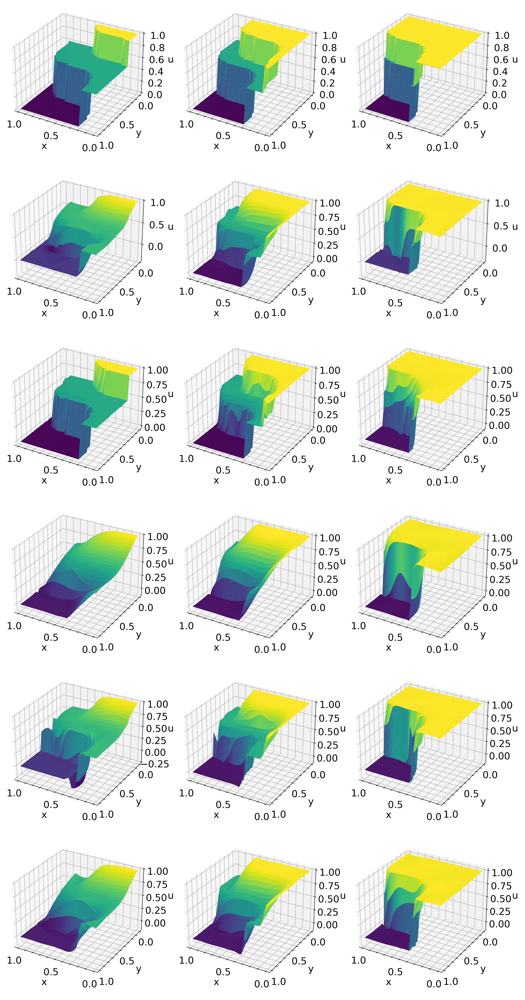

[Saved] evaluation\gkhm2d\paper_figures\Figure22_rows6_part2.png


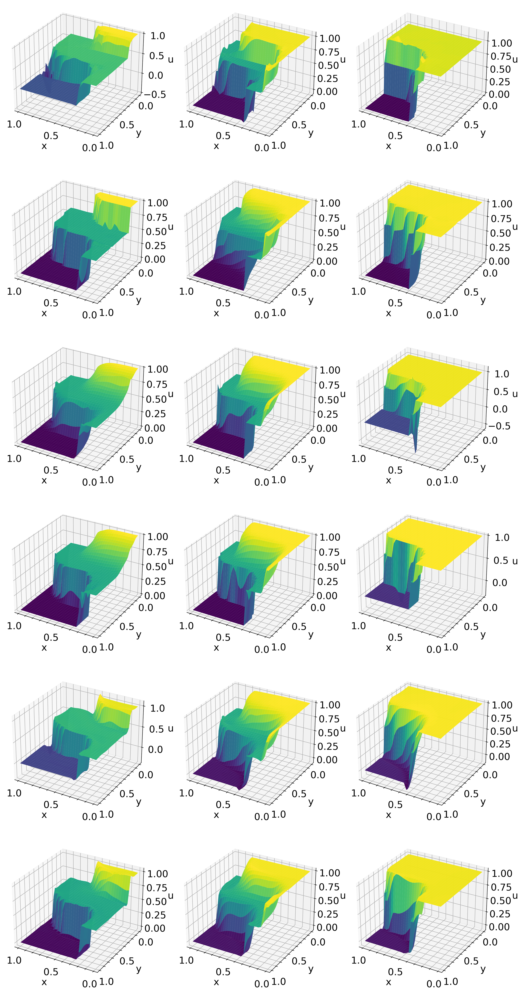

In [18]:
"""Arrange evaluation PNGs using an editable row-by-row LAYOUT.
Install: pip install pillow
Run from the project directory: python assemble_guckenheimer_figure.py
No panel letters, model names, or time headings are added.
PDF embeds raster images; it does not convert them into vector plots.
"""
from pathlib import Path
import csv
import re
from PIL import Image, ImageChops
from IPython.display import display, Image as NotebookImage

EVALUATION_ROOT = Path("evaluation/gkhm2d")
SEED = None
REFERENCE_METHOD = "Conventional"
TIMES = (0.0, 0.3, 0.6)
OUTPUT_DIR = EVALUATION_ROOT / "paper_figures"
OUTPUT_NAME = "Figure20_selected_seeds"

CELL_WIDTH = 1000
CELL_HEIGHT = 900
COLUMN_GAP = 20
ROW_GAP = 90
OUTER_MARGIN = 35
DPI = 300
ROW_ALIGN = "center"
COLUMN_GAPS = {}
ROW_GAPS = {}
CROP_WHITE_MARGIN = True
WHITE_TOLERANCE = 8
CROP_PADDING = 14
SCALE_MODE = "common"
ALLOW_UPSCALE = False

ROWS_PER_BLOCK = 6
BLOCK_GAP = 150
PREVIEW_WIDTH = 1200
FILE_PREFIX = "Figure22"

def panel(method, time, kind="prediction", seed=None):
    """One evaluation image; seed=None uses SEED (auto-select @ when SEED=None). kind: prediction/reference."""
    return dict(method=method, time=time, kind=kind, seed=seed)

def series(method, times=None, kind="prediction", seed=None):
    """A row segment; change TIMES once to update every default segment."""
    return [panel(method, t, kind, seed) for t in (TIMES if times is None else times)]

def method_directory(root, name):
    exact = root / name
    if exact.is_dir():
        return exact
    matches = [p for p in root.iterdir() if p.is_dir() and p.name.lower() == name.lower()]
    if len(matches) == 1:
        return matches[0]
    raise FileNotFoundError(f"Method folder missing or ambiguous: {exact}")

def select_seed_directory(root, method, seed=None):
    method_dir = method_directory(root, method)
    candidates = []
    for directory in method_dir.iterdir():
        if not directory.is_dir():
            continue
        match = re.fullmatch(r"seed(\d+)", directory.name.replace("@", "").strip(), flags=re.IGNORECASE)
        if match is None:
            continue
        number = int(match.group(1))
        if (seed is None and "@" in directory.name) or (seed is not None and number == int(seed)):
            candidates.append((number, directory))
    if len(candidates) != 1:
        request = "one @-marked seed folder" if seed is None else f"one folder for seed{seed}"
        raise FileNotFoundError(
            f"Expected {request}; found {len(candidates)}.\n"
            f"Method folder: {method_dir}\nCandidates: {[p.name for _, p in candidates]}"
        )
    return candidates[0]

def find_surface(root, method, seed, time, kind):
    actual_seed, seed_dir = select_seed_directory(root, method, seed)
    directory = seed_dir / f"{kind}_surface"
    tag = f"{time:.6f}".replace(".", "p")
    matches = sorted(directory.glob(f"*_seed{actual_seed}_t{tag}.png"))
    if len(matches) != 1:
        raise FileNotFoundError(
            f"Expected exactly one surface for t={time:g}; found {len(matches)}.\n"
            f"Folder: {directory}\nPattern: *_seed{actual_seed}_t{tag}.png"
        )
    return matches[0]

def load_surface(path):
    with Image.open(path) as source:
        rgba = source.convert("RGBA")
        white = Image.new("RGBA", rgba.size, "white")
        white.alpha_composite(rgba)
        image = white.convert("RGB")
    if CROP_WHITE_MARGIN:
        difference = ImageChops.difference(image, Image.new("RGB", image.size, "white"))
        channels = difference.split()
        mask = ImageChops.lighter(ImageChops.lighter(channels[0], channels[1]), channels[2])
        box = mask.point(lambda value: 255 if value > WHITE_TOLERANCE else 0).getbbox()
        if box is None:
            raise ValueError(f"Blank surface image: {path}")
        x0, y0, x1, y1 = box
        box = (max(0, x0-CROP_PADDING), max(0, y0-CROP_PADDING),
               min(image.width, x1+CROP_PADDING), min(image.height, y1+CROP_PADDING))
        image = image.crop(box)
    return image

def main(root=None, output_dir=None, layout=None):
    root = Path(EVALUATION_ROOT if root is None else root)
    output_dir = Path(OUTPUT_DIR if output_dir is None else output_dir)
    layout = LAYOUT if layout is None else layout
    if min(CELL_WIDTH, CELL_HEIGHT, DPI) <= 0 or min(COLUMN_GAP, ROW_GAP, OUTER_MARGIN) < 0:
        raise ValueError("Invalid image size, resolution, or spacing.")
    if any(v < 0 for v in (*COLUMN_GAPS.values(), *ROW_GAPS.values())):
        raise ValueError("Gaps must be non-negative.")
    if SCALE_MODE not in ("common", "fit"):
        raise ValueError("SCALE_MODE must be common or fit.")
    rows = []
    for row in layout:
        cells = row["cells"] if isinstance(row, dict) else row
        align = row.get("align", ROW_ALIGN) if isinstance(row, dict) else ROW_ALIGN
        if align not in ("left", "center", "right") or not cells:
            raise ValueError("Each row needs cells and a valid alignment.")
        rows.append((cells, align))
    if not rows:
        raise ValueError("LAYOUT is empty.")

    def row_width(cells):
        return len(cells)*CELL_WIDTH + sum(COLUMN_GAPS.get(c, COLUMN_GAP) for c in range(len(cells)-1))

    entries = []
    for r, (cells, _) in enumerate(rows):
        for c, item in enumerate(cells):
            if item is None:
                continue
            if isinstance(item, (str, Path)):
                path = Path(item)
                info = dict(method="", time="", seed="", kind="explicit")
            else:
                info = dict(item)
                requested_seed = SEED if info.get("seed") is None else info["seed"]
                info["seed"], seed_dir = select_seed_directory(root, info["method"], requested_seed)
                path = find_surface(root, info["method"], info["seed"], info["time"], info.get("kind", "prediction"))
            if not path.is_file():
                raise FileNotFoundError(path)
            entries.append((r, c, info, path))
    if not entries:
        raise ValueError("LAYOUT contains no images.")
    dimensions = [load_surface(path).size for _, _, _, path in entries]
    common_scale = min(CELL_WIDTH/max(w for w, h in dimensions), CELL_HEIGHT/max(h for w, h in dimensions))
    if not ALLOW_UPSCALE:
        common_scale = min(1.0, common_scale)
    content_width = max(row_width(cells) for cells, _ in rows)
    width = 2*OUTER_MARGIN + content_width
    height = 2*OUTER_MARGIN + len(rows)*CELL_HEIGHT + sum(ROW_GAPS.get(r, ROW_GAP) for r in range(len(rows)-1))
    canvas = Image.new("RGB", (width, height), "white")
    for r, c, info, path in entries:
        cells, align = rows[r]
        extra = content_width-row_width(cells)
        shift = {"left": 0, "center": extra//2, "right": extra}[align]
        x = OUTER_MARGIN+shift+c*CELL_WIDTH+sum(COLUMN_GAPS.get(k, COLUMN_GAP) for k in range(c))
        y = OUTER_MARGIN+r*CELL_HEIGHT+sum(ROW_GAPS.get(k, ROW_GAP) for k in range(r))
        image = load_surface(path)
        scale = common_scale if SCALE_MODE == "common" else min(CELL_WIDTH/image.width, CELL_HEIGHT/image.height)
        if not ALLOW_UPSCALE:
            scale = min(1.0, scale)
        size = (max(1, round(image.width*scale)), max(1, round(image.height*scale)))
        image = image.resize(size, Image.Resampling.LANCZOS)
        canvas.paste(image, (x+(CELL_WIDTH-image.width)//2, y+(CELL_HEIGHT-image.height)//2))
    output_dir.mkdir(parents=True, exist_ok=True)
    png_path = output_dir / f"{OUTPUT_NAME}.png"
    canvas.save(png_path, dpi=(DPI, DPI))

    with (output_dir / f"{OUTPUT_NAME}_sources.csv").open(
        "w", newline="", encoding="utf-8-sig"
    ) as stream:
        writer = csv.writer(stream)
        writer.writerow(("row", "column", "method", "time", "seed", "kind", "source"))
        writer.writerows(
            (r + 1, c + 1, info.get("method", ""), info.get("time", ""),
             info.get("seed", ""), info.get("kind", "prediction"), str(path))
            for r, c, info, path in entries
        )

    print(f"[Saved] {png_path}")
    return png_path

MODEL_ROWS = [
    series(REFERENCE_METHOD, kind="reference"),
    series("Conventional"),
    series("NTK"),
    series("SA"),
    series("Causal"),
    series("rba"),
    series("brdr"),
    series("aSA"),
    series("SLFormer_Single(NoSlope)"),
    series("SLFormer(NoSlope)"),
    series("SLFormer_Single"),
    series("SLFormer"),
]

if not isinstance(ROWS_PER_BLOCK, int) or ROWS_PER_BLOCK < 1:
    raise ValueError("ROWS_PER_BLOCK must be a positive integer.")

COLUMN_GAPS = {}
ROW_GAPS = {}

for part, start in enumerate(
    range(0, len(MODEL_ROWS), ROWS_PER_BLOCK), start=1
):
    layout = MODEL_ROWS[start:start + ROWS_PER_BLOCK]
    OUTPUT_NAME = f"{FILE_PREFIX}_rows{ROWS_PER_BLOCK}_part{part}"

    png_path = main(layout=layout)
    display(NotebookImage(filename=str(png_path), width=PREVIEW_WIDTH))
